### dataset sakaguchi2025brazilian,

  author = {Richard Sakaguchi},

  title = {Brazilian Customer Service Conversations},

  year = {2025},

  publisher = {Hugging Face},

  url = {https://huggingface.co/datasets/RichardSakaguchiMS/brazilian-customer-service-conversations }



### Benchmark
Classificacao de Intencao: F1-Score	~0.72

Analise de Sentimento	Accuracy	~0.78

### 0. Carregando dataset

In [ ]:
from datasets import load_dataset

dataset = load_dataset("RichardSakaguchiMS/brazilian-customer-service-conversations")

train = dataset["train"]
validation = dataset["validation"]
test = dataset["test"]

README.md:   0%|          | 0.00/3.79k [00:00<?, ?B/s]

train.jsonl:   0%|          | 0.00/1.12M [00:00<?, ?B/s]

validation.jsonl:   0%|          | 0.00/140k [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/138k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/755 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/94 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/95 [00:00<?, ? examples/s]

In [ ]:
# Classificação de intenção
# Treino
X = [ex["messages"][0]["content"] for ex in dataset["train"]]
y = [ex["metadata"]["intent"] for ex in dataset["train"]]

# Validação
X_val = [ex["messages"][0]["content"] for ex in dataset["validation"]]
y_val = [ex["metadata"]["intent"] for ex in dataset["validation"]]

In [ ]:
# Analise de sentimento
# Treino
texts = [" ".join([m["content"] for m in ex["messages"]]) for ex in dataset["train"]]
labels = [ex["metadata"]["sentiment"] for ex in dataset["train"]]

# Validação
texts_val = [" ".join([m["content"] for m in ex["messages"]]) for ex in dataset["validation"]]
labels_val = [ex["metadata"]["sentiment"] for ex in dataset["validation"]]

### 1. Codificação das Labels
Transformando os textos das labels em valores numéricos compreensíveis pelo modelo.

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Encode para Intenções
intent_encoder = LabelEncoder()
y_encoded = intent_encoder.fit_transform(y)
y_val_encoded = intent_encoder.transform(y_val) # usar apenas transform na validação
num_intent_labels = len(intent_encoder.classes_)
print(f"Classes de intenção ({num_intent_labels}): {intent_encoder.classes_}")

# Encode para Sentimentos
sentiment_encoder = LabelEncoder()
labels_encoded = sentiment_encoder.fit_transform(labels)
labels_val_encoded = sentiment_encoder.transform(labels_val)
num_sentiment_labels = len(sentiment_encoder.classes_)
print(f"Classes de sentimento ({num_sentiment_labels}): {sentiment_encoder.classes_}")

Classes de intenção (9): ['cancelamento' 'compra' 'duvida_produto' 'duvida_servico' 'elogio'
 'outros' 'reclamacao' 'saudacao' 'suporte_tecnico']
Classes de sentimento (3): ['negative' 'neutral' 'positive']


### 2. Tokenização com BERTimbau
Carregando o tokenizador do modelo `neuralmind/bert-base-portuguese-cased` para processar nossos textos.

In [ ]:
from transformers import AutoTokenizer

model_name = "neuralmind/bert-base-portuguese-cased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Tokenizando os dados de intenção
intent_encodings = tokenizer(X, truncation=True, padding=True, max_length=128)
intent_val_encodings = tokenizer(X_val, truncation=True, padding=True, max_length=128)

# Tokenizando os dados de sentimento
sentiment_encodings = tokenizer(texts, truncation=True, padding=True, max_length=512)
sentiment_val_encodings = tokenizer(texts_val, truncation=True, padding=True, max_length=512)

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

### 3. Classe Dataset customizada (PyTorch)
O Hugging Face `Trainer` espera que os dados sejam fornecidos através de um Dataset do PyTorch.

In [ ]:
import torch

class ConversationDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)

# Instanciando datasets de treino e validação
intent_dataset = ConversationDataset(intent_encodings, y_encoded)
intent_val_dataset = ConversationDataset(intent_val_encodings, y_val_encoded)

sentiment_dataset = ConversationDataset(sentiment_encodings, labels_encoded)
sentiment_val_dataset = ConversationDataset(sentiment_val_encodings, labels_val_encoded)

### 4. Modelo de Classificação de Intenção
Configurando o modelo para prever a intenção do cliente com base na primeira mensagem.

In [ ]:
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments

# Carregando modelo base e ajustando o cabeçalho de classificação
intent_model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=num_intent_labels)

intent_training_args = TrainingArguments(
    output_dir='./results_intent',
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy="epoch", # Avaliar o modelo ao final de cada época
    logging_steps=10,
    save_steps=50,
)

intent_trainer = Trainer(
    model=intent_model,
    args=intent_training_args,
    train_dataset=intent_dataset,
    eval_dataset=intent_val_dataset, # Passando o conjunto de validação
)

# Para iniciar o treinamento da intenção, descomente a linha abaixo e execute:
intent_trainer.train()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

Epoch,Training Loss,Validation Loss
1,1.082394,0.843758
2,0.469964,0.528060
3,0.359055,0.477765


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=285, training_loss=0.8082434558031851, metrics={'train_runtime': 18.7276, 'train_samples_per_second': 120.945, 'train_steps_per_second': 15.218, 'total_flos': 79154124433560.0, 'train_loss': 0.8082434558031851, 'epoch': 3.0})

### 5. Modelo de Análise de Sentimento
Configurando o segundo modelo para analisar o sentimento da conversa por completo.

In [ ]:
# Carregando modelo base e ajustando o cabeçalho de classificação (independente do primeiro)
sentiment_model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=num_sentiment_labels)

sentiment_training_args = TrainingArguments(
    output_dir='./results_sentiment',
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy="epoch", # Avaliar o modelo ao final de cada época
    logging_steps=10,
    save_steps=50,
)

sentiment_trainer = Trainer(
    model=sentiment_model,
    args=sentiment_training_args,
    train_dataset=sentiment_dataset,
    eval_dataset=sentiment_val_dataset, # Passando o conjunto de validação
)

# Para iniciar o treinamento de sentimento, descomente a linha abaixo e execute:
sentiment_trainer.train()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

Epoch,Training Loss,Validation Loss
1,0.541694,0.430183
2,0.358730,0.364127
3,0.388400,0.453523


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=285, training_loss=0.505302440806439, metrics={'train_runtime': 21.5035, 'train_samples_per_second': 105.332, 'train_steps_per_second': 13.254, 'total_flos': 505162345235940.0, 'train_loss': 0.505302440806439, 'epoch': 3.0})

### 6. Análise de Treinamento: Curvas de Aprendizado (Loss)
Vamos extrair os dados do `log_history` de cada `Trainer` e plotar as curvas de loss de treino e validação ao longo das épocas (ou steps).

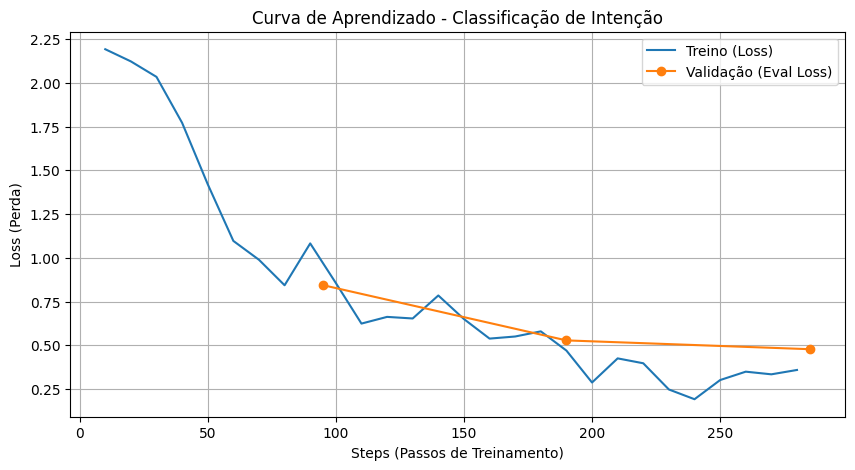

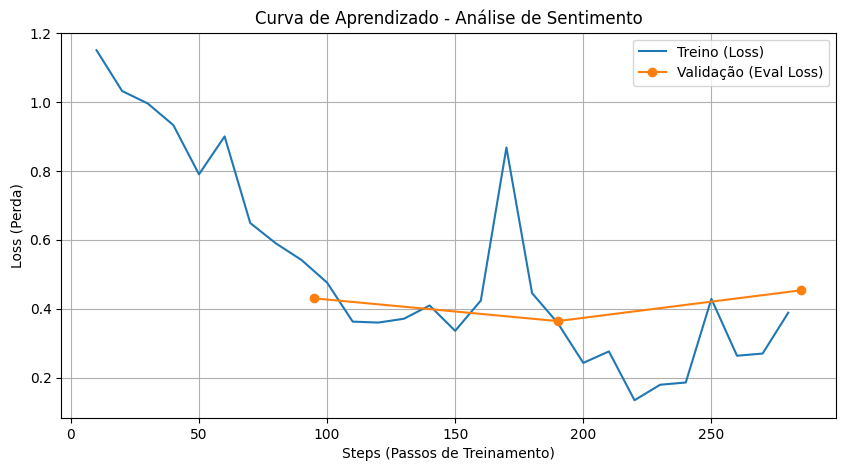

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_loss(log_history, title):
    # Separando logs de treino e avaliação
    train_logs = [log for log in log_history if 'loss' in log and 'step' in log]
    eval_logs = [log for log in log_history if 'eval_loss' in log and 'step' in log]

    df_train = pd.DataFrame(train_logs)
    df_eval = pd.DataFrame(eval_logs)

    plt.figure(figsize=(10, 5))
    if not df_train.empty:
        plt.plot(df_train['step'], df_train['loss'], label='Treino (Loss)')
    if not df_eval.empty:
        plt.plot(df_eval['step'], df_eval['eval_loss'], label='Validação (Eval Loss)', marker='o')

    plt.title(title)
    plt.xlabel('Steps (Passos de Treinamento)')
    plt.ylabel('Loss (Perda)')
    plt.legend()
    plt.grid(True)
    plt.show()

# Plotando para o modelo de Intenção
plot_loss(intent_trainer.state.log_history, "Curva de Aprendizado - Classificação de Intenção")

# Plotando para o modelo de Sentimento
plot_loss(sentiment_trainer.state.log_history, "Curva de Aprendizado - Análise de Sentimento")

### 7. Métricas Finais: Acurácia e Classification Report
Aqui avaliaremos o desempenho final de cada modelo usando o conjunto de validação para verificar como ele se saiu na classificação das categorias.

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

# ==========================================
# 1. Resultados para Intenção
# ==========================================
print("Gerando previsões para Intenção...")
intent_preds = intent_trainer.predict(intent_val_dataset)
y_pred_intent = np.argmax(intent_preds.predictions, axis=1)

print("\n=== Resultados: Classificação de Intenção ===")
print(f"Acurácia: {accuracy_score(y_val_encoded, y_pred_intent):.4f}")
print("\nRelatório de Classificação:")
print(classification_report(y_val_encoded, y_pred_intent, target_names=intent_encoder.classes_))

print("\n" + "="*60 + "\n")

# ==========================================
# 2. Resultados para Sentimento
# ==========================================
print("Gerando previsões para Sentimento...")
sentiment_preds = sentiment_trainer.predict(sentiment_val_dataset)
y_pred_sentiment = np.argmax(sentiment_preds.predictions, axis=1)

print("\n=== Resultados: Análise de Sentimento ===")
print(f"Acurácia: {accuracy_score(labels_val_encoded, y_pred_sentiment):.4f}")
print("\nRelatório de Classificação:")
print(classification_report(labels_val_encoded, y_pred_sentiment, target_names=sentiment_encoder.classes_))

Gerando previsões para Intenção...



=== Resultados: Classificação de Intenção ===
Acurácia: 0.8723

Relatório de Classificação:
                 precision    recall  f1-score   support

   cancelamento       1.00      1.00      1.00        10
         compra       0.81      0.93      0.87        14
 duvida_produto       0.84      0.94      0.89        17
 duvida_servico       1.00      1.00      1.00         8
         elogio       1.00      0.57      0.73         7
         outros       0.71      0.71      0.71         7
     reclamacao       1.00      0.62      0.76        13
       saudacao       0.89      1.00      0.94         8
suporte_tecnico       0.77      1.00      0.87        10

       accuracy                           0.87        94
      macro avg       0.89      0.86      0.86        94
   weighted avg       0.89      0.87      0.87        94



Gerando previsões para Sentimento...



=== Resultados: Análise de Sentimento ===
Acurácia: 0.9043

Relatório de Classificação:
              precision    recall  f1-score   support

    negative       1.00      0.94      0.97        36
     neutral       0.79      0.96      0.87        24
    positive       0.90      0.82      0.86        34

    accuracy                           0.90        94
   macro avg       0.90      0.91      0.90        94
weighted avg       0.91      0.90      0.91        94



### 8. Testando com frases personalizadas
Função para enviar frases arbitrárias para o modelo e ver como ele se comporta no mundo real.

In [ ]:
import torch

def testar_modelos(texto):
    # Tokenizar o texto de entrada
    inputs = tokenizer(texto, return_tensors="pt", truncation=True, padding=True, max_length=512)

    # Enviar os tensores para o mesmo dispositivo (CPU ou GPU) onde os modelos estão
    device = intent_model.device
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Usar torch.no_grad() pois não estamos treinando, apenas inferindo
    with torch.no_grad():
        # Inferência de Intenção
        intent_outputs = intent_model(**inputs)
        intent_pred_id = torch.argmax(intent_outputs.logits, dim=1).cpu().numpy()[0]
        intent_label = intent_encoder.inverse_transform([intent_pred_id])[0]

        # Inferência de Sentimento
        sentiment_outputs = sentiment_model(**inputs)
        sentiment_pred_id = torch.argmax(sentiment_outputs.logits, dim=1).cpu().numpy()[0]
        sentiment_label = sentiment_encoder.inverse_transform([sentiment_pred_id])[0]

    print(f"Mensagem: '{texto}'")
    print(f"🎯 Intenção:   {intent_label}")
    print(f"🎭 Sentimento: {sentiment_label}")
    print("-" * 60)

# Exemplos de teste
frases_teste = [
    "Oi, minha internet está caindo toda hora, que serviço horrível! Quero cancelar agora!",
    "Bom dia, vocês teriam o iPhone 13 em estoque?",
    "Muito obrigado pela ajuda! O atendente foi super rápido e educado, resolveu meu problema.",
    "Como faço para resetar a senha do meu roteador?"
]

for frase in frases_teste:
    testar_modelos(frase)

Mensagem: 'Oi, minha internet está caindo toda hora, que serviço horrível! Quero cancelar agora!'
🎯 Intenção:   cancelamento
🎭 Sentimento: negative
------------------------------------------------------------
Mensagem: 'Bom dia, vocês teriam o iPhone 13 em estoque?'
🎯 Intenção:   duvida_produto
🎭 Sentimento: neutral
------------------------------------------------------------
Mensagem: 'Muito obrigado pela ajuda! O atendente foi super rápido e educado, resolveu meu problema.'
🎯 Intenção:   elogio
🎭 Sentimento: positive
------------------------------------------------------------
Mensagem: 'Como faço para resetar a senha do meu roteador?'
🎯 Intenção:   suporte_tecnico
🎭 Sentimento: neutral
------------------------------------------------------------


### 9. Salvando os modelos para uso futuro
Exportando os modelos, o tokenizador e os encoders para pastas locais.

In [ ]:
import joblib
import os

# Criando os diretórios para salvar os modelos
dir_intencao = './modelo_intencao_salvo'
dir_sentimento = './modelo_sentimento_salvo'
os.makedirs(dir_intencao, exist_ok=True)
os.makedirs(dir_sentimento, exist_ok=True)

# ==========================================
# 1. Salvando Modelo de Intenção
# ==========================================
intent_model.save_pretrained(dir_intencao)
tokenizer.save_pretrained(dir_intencao)
joblib.dump(intent_encoder, os.path.join(dir_intencao, 'intent_encoder.joblib'))
print(f"✅ Modelo de Intenção, Tokenizador e Encoder salvos em '{dir_intencao}'")

# ==========================================
# 2. Salvando Modelo de Sentimento
# ==========================================
sentiment_model.save_pretrained(dir_sentimento)
tokenizer.save_pretrained(dir_sentimento)
joblib.dump(sentiment_encoder, os.path.join(dir_sentimento, 'sentiment_encoder.joblib'))
print(f"✅ Modelo de Sentimento, Tokenizador e Encoder salvos em '{dir_sentimento}'")

print("\nAgora você pode baixar essas pastas para o seu computador ou enviá-las para a nuvem/Hugging Face Hub!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Modelo de Intenção, Tokenizador e Encoder salvos em './modelo_intencao_salvo'


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Modelo de Sentimento, Tokenizador e Encoder salvos em './modelo_sentimento_salvo'

Agora você pode baixar essas pastas para o seu computador ou enviá-las para a nuvem/Hugging Face Hub!


### 10. Baixando os modelos para o seu computador
Compactando as pastas em arquivos `.zip` para facilitar o download.

In [ ]:
import shutil
from google.colab import files

print("Compactando o modelo de Intenção...")
shutil.make_archive('modelo_intencao', 'zip', dir_intencao)

print("Compactando o modelo de Sentimento...")
shutil.make_archive('modelo_sentimento', 'zip', dir_sentimento)

print("Iniciando os downloads! (Verifique os pop-ups do seu navegador)")
files.download('modelo_intencao.zip')
files.download('modelo_sentimento.zip')

Compactando o modelo de Intenção...
Compactando o modelo de Sentimento...
Iniciando os downloads! (Verifique os pop-ups do seu navegador)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>